This notebook is basically just a sanity check that the dataloader works

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
import random

# ARITHMETIC DATASET CLASS
class ArithmeticDataset(Dataset):
    """
    getitem returns: context_img, ctx_label, operation, target_img, target_label
    """
    def __init__(self, base_dataset, operations, transform=None):
        self.base_dataset = base_dataset

        # CURRENTLY ONLY SUPPORTS ADDITION/SUBTRACTION
        self.operations = operations # e.g. [1, 2, -1, -2]
        self.transform = transform

        # Pre-index labels to find target images quickly
        # (Apparently this is more efficient)
        self.label_to_indices = self._index_labels()
        self.num_classes = len(self.label_to_indices.keys())

    def _index_labels(self):
        idx_map = {}
        for i in range(len(self.base_dataset)):
            _, label = self.base_dataset[i]
            if label not in idx_map:
                idx_map[label] = []
            idx_map[label].append(i)
        return idx_map

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        # State t: Context
        ctx_img, ctx_label = self.base_dataset[idx]

        # Transformation: Randomly select an operation from the allowed list
        op_val = random.choice(self.operations)

        # State t+1: Calculate target label (modular arithmetic)
        # e.g. (9 + 2) % 10 = 1
        tgt_label = (ctx_label + op_val) % self.num_classes

        # Retrieve random target image of that class (ensures latent invariance)
        tgt_idx = random.choice(self.label_to_indices[tgt_label])
        tgt_img, _ = self.base_dataset[tgt_idx]

        if self.transform:
            ctx_img = self.transform(ctx_img)
            tgt_img = self.transform(tgt_img)

        return {
            "ctx_img": ctx_img,
            "ctx_label": torch.tensor(ctx_label),
            "op": torch.tensor(op_val, dtype=torch.float32),
            "tgt_img": tgt_img,
            "tgt_label": torch.tensor(tgt_label)
        }

In [2]:
def get_arithmetic_dataloader(dataset_name="MNIST", batch_size=64, ops=[1, 2, -1, -2], is_train=True):
    """
    Factory function to easily create loaders for MNIST or EMNIST.
    """
    # Standard MNIST/EMNIST normalization constants
    t = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])

    if dataset_name.upper() == "MNIST":
        base = datasets.MNIST(root='./data', train=is_train, download=True)
    elif dataset_name.upper() == "EMNIST":
        base = datasets.EMNIST(root='./data', split='digits', train=is_train, download=True)
    else:
        raise ValueError("Only MNIST and EMNIST are currently supported.")

    arith_ds = ArithmeticDataset(base, operations=ops, transform=t)

    return DataLoader(arith_ds, batch_size=batch_size, shuffle=is_train)

In [3]:
dataloader = get_arithmetic_dataloader()

100%|██████████| 9.91M/9.91M [00:00<00:00, 139MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 33.3MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 85.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.51MB/s]


In [4]:
# VISUALIZATION (aka sanity check)
# This block is 100% chatgpt I'm not gonna lie
def visualize_batch(batch):
    cols = 4
    rows = 2
    fig, axes = plt.subplots(rows, cols, figsize=(15, 8))
    fig.suptitle("Data Batch", fontsize=16)

    for i in range(rows * cols):
        ax = axes[i // cols, i % cols]

        # Un-normalize for display
        ctx = batch['ctx_img'][i].squeeze().numpy() * 0.3081 + 0.1307
        tgt = batch['tgt_img'][i].squeeze().numpy() * 0.3081 + 0.1307

        # Create a combined image [Context | Target]
        combined = np.hstack((ctx, np.ones((28, 5)), tgt)) # Add white spacer

        ax.imshow(combined, cmap='gray')
        op_sign = f"+{int(batch['op'][i])}" if batch['op'][i] > 0 else f"{int(batch['op'][i])}"
        ax.set_title(f"Ctx: {batch['ctx_label'][i]} | Op: {op_sign} | Tgt: {batch['tgt_label'][i]}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

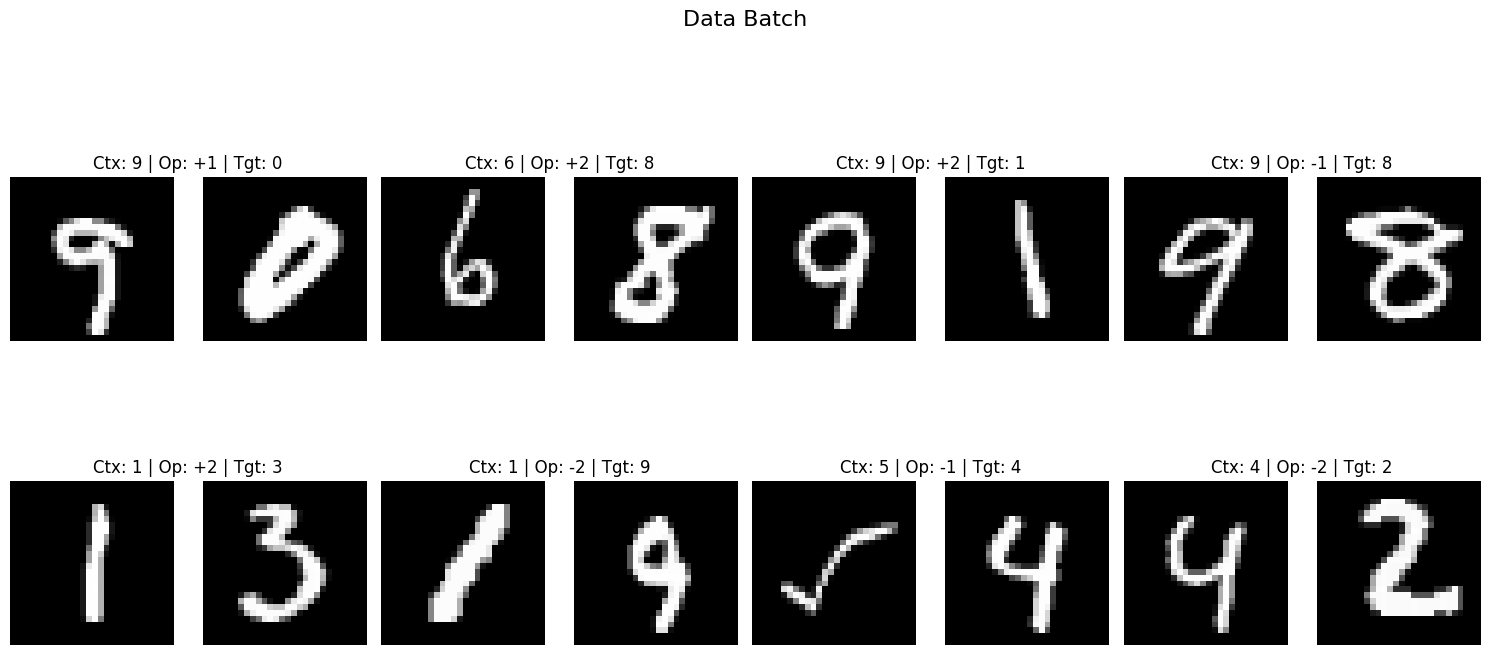

In [5]:
# Execute
batch = next(iter(dataloader))
visualize_batch(batch)